# 2.3 Exploratory Data Analysis (EDA) — Georgia
**DTU 42577 · Group 17 · Powering Palo Alto**

The plots describe the cleaned **session-level** data. A session start is *not* the same as hourly charger occupation or hourly energy demand. For actual hourly energy/occupation, use the hourly-transformed data in `2. Data Modelling.ipynb`.

## Input and methodological safeguards
Run the group preprocessing notebook (`project.ipynb`, Sections 1.1–1.5) first so that `Data/ev_clean.pkl` exists. **Do not re-clean** the raw CSV independently. The dataset is restricted to start dates before March 2020. Station histories are different lengths, so raw totals do not measure utilization. Physical cleaning removed extreme durations above 24 hours, so idle-time tails are truncated by design.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
p = Path("Data/ev_clean.pkl")
if not p.exists():
    raise FileNotFoundError("Run project.ipynb preprocessing first to create Data/ev_clean.pkl")
ev = pd.read_pickle(p).copy()
ev["year"] = ev["start"].dt.year
ev["month"] = ev["start"].dt.to_period("M")
ev["hour"] = ev["start"].dt.hour
ev["weekday"] = ev["start"].dt.day_name()
ev["is_weekend"] = ev["start"].dt.dayofweek >= 5
print(f"Rows: {len(ev):,}; stations: {ev['station'].nunique()}; period: {ev['start'].min()} to {ev['start'].max()}")
assert len(ev)==245736, "Dataset differs from the current group's reported clean version; reconcile before reporting."


Rows: 245,736; stations: 33; period: 2011-07-29 20:17:00 to 2020-02-29 21:47:00


## 2.3.1 Activity over time
**Question:** How did recorded charging activity evolve? **Caution:** Changes can reflect an expanding station network as well as changing user demand. Do not infer growth in per-charger utilization from network totals.

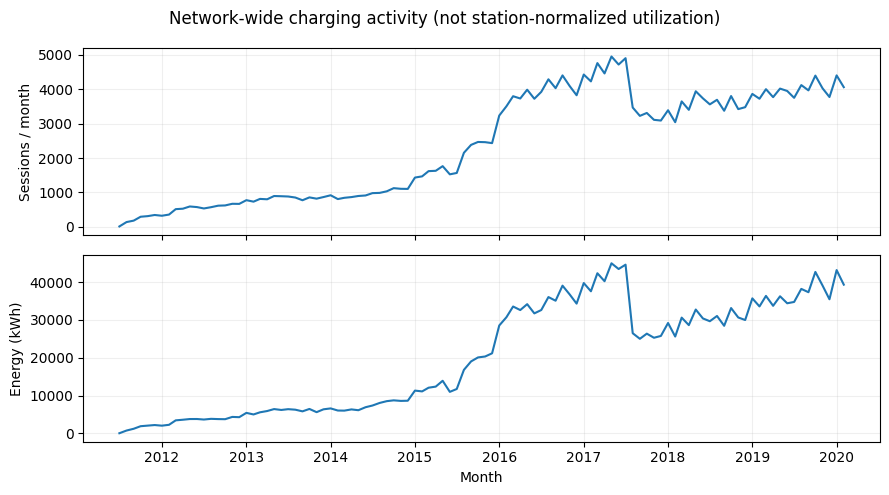

In [2]:
monthly = (ev.groupby("month").agg(sessions=("energy_kwh", "size"), energy=("energy_kwh", "sum")))
monthly.index = monthly.index.to_timestamp()
fig, ax = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
ax[0].plot(monthly.index, monthly["sessions"]); ax[0].set_ylabel("Sessions / month")
ax[1].plot(monthly.index, monthly["energy"]); ax[1].set_ylabel("Energy (kWh)"); ax[1].set_xlabel("Month")
for a in ax: a.grid(alpha=.2)
fig.suptitle("Network-wide charging activity (not station-normalized utilization)")
plt.tight_layout(); plt.show()


## 2.3.2 Charging start times by weekday and hour
**Question:** When do charging sessions start? These counts reflect **plug-in arrivals**, not necessarily energy used or port occupancy at that hour.

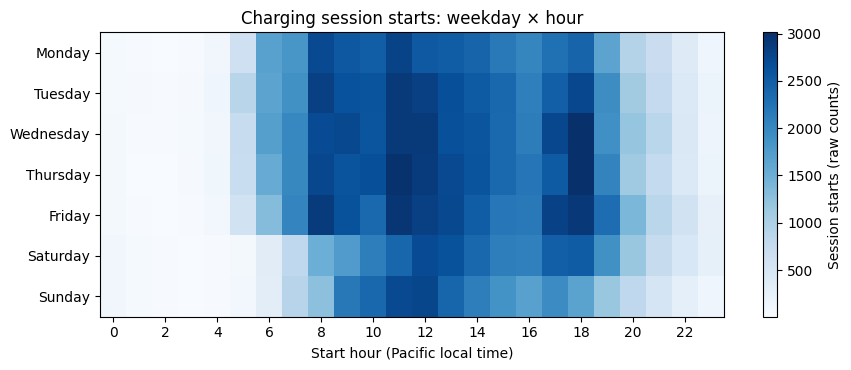

Peak start hour: 11


In [3]:
days=["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
ev["weekday"] = pd.Categorical(ev["weekday"],categories=days,ordered=True)
heat = pd.crosstab(ev["weekday"],ev["hour"]).reindex(index=days,columns=range(24),fill_value=0)
fig,ax=plt.subplots(figsize=(9,3.8)); im=ax.imshow(heat,aspect="auto",cmap="Blues")
ax.set(yticks=range(7),yticklabels=days,xticks=range(0,24,2),xticklabels=range(0,24,2),xlabel="Start hour (Pacific local time)",title="Charging session starts: weekday × hour")
fig.colorbar(im,ax=ax,label="Session starts (raw counts)");plt.tight_layout();plt.show()
print("Peak start hour:",ev["hour"].value_counts().idxmax())


## 2.3.3 Differences between stations
**Question:** Which locations record the most charging sessions? **Caution:** Station totals are influenced by years observed, port numbers, and periods of apparent inactivity. Do not call these the most *utilized* stations without an exposure/availability denominator.

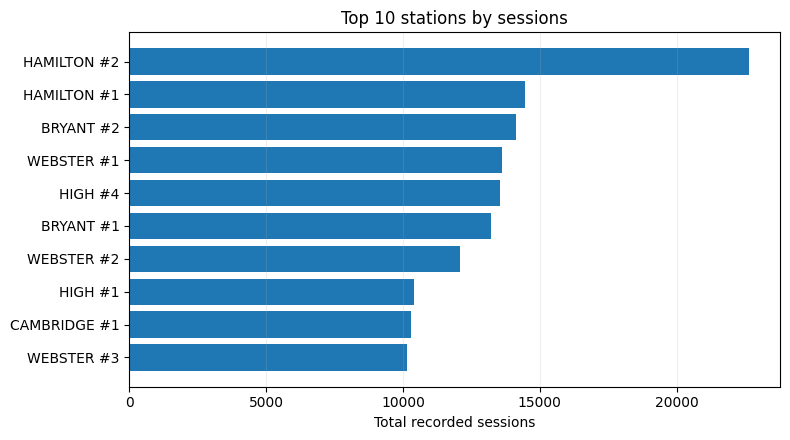

,sessions,energy_kwh
station,,
PALO ALTO CA / HAMILTON #2,22648,181843.614638
PALO ALTO CA / HAMILTON #1,14455,110806.156688
PALO ALTO CA / BRYANT #2,14126,106551.845312
PALO ALTO CA / WEBSTER #1,13601,130362.023451
PALO ALTO CA / HIGH #4,13540,109292.463078
PALO ALTO CA / BRYANT #1,13222,101746.150054
PALO ALTO CA / WEBSTER #2,12085,119856.981422
PALO ALTO CA / HIGH #1,10414,94920.559578
PALO ALTO CA / CAMBRIDGE #1,10300,74371.600354


In [4]:
st = ev.groupby("station",observed=True).agg(sessions=("start","size"), energy_kwh=("energy_kwh","sum")).sort_values("sessions",ascending=False)
top=st.head(10)
fig,ax=plt.subplots(figsize=(8,4.5));ax.barh(top.index.astype(str).str.replace("PALO ALTO CA / ","",regex=False)[::-1],top["sessions"].to_numpy()[::-1])
ax.set(xlabel="Total recorded sessions",title="Top 10 stations by sessions");ax.grid(axis="x",alpha=.2);plt.tight_layout();plt.show()
display(st.head(10))


## 2.3.4 Session duration, charging duration and idle time
**Question:** How long do vehicles remain plugged in after charging? `idle_hours = total_hours − charging_hours`, already calculated in the preprocessing notebook. A threshold such as >1 h describes potentially inefficient occupation; it is an *operational definition*, not a validated measure of lost revenue.

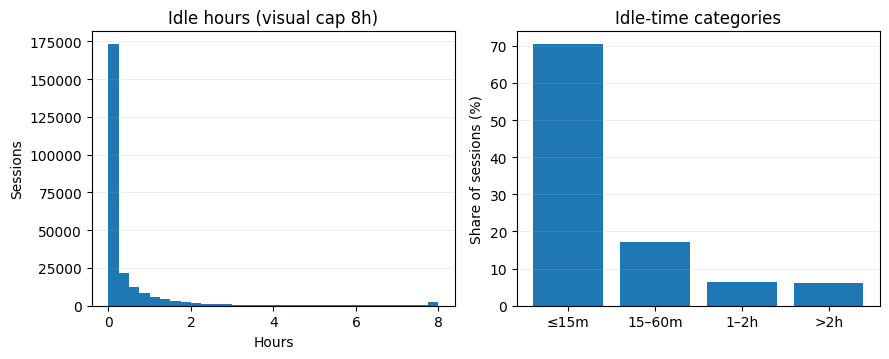

Idle >1 h: 12.37% | Idle >2 h: 6.05%


In [5]:
idle=ev["idle_hours"].clip(lower=0)
fig,axes=plt.subplots(1,2,figsize=(9,3.7))
axes[0].hist(idle.clip(upper=8),bins=np.arange(0,8.25,.25)); axes[0].set(title="Idle hours (visual cap 8h)",xlabel="Hours",ylabel="Sessions")
bins=[(idle<=.25).sum(),((idle>.25)&(idle<=1)).sum(),((idle>1)&(idle<=2)).sum(),(idle>2).sum()]
axes[1].bar(["≤15m","15–60m","1–2h",">2h"],np.array(bins)/len(ev)*100); axes[1].set(title="Idle-time categories",ylabel="Share of sessions (%)")
for a in axes:a.grid(axis="y",alpha=.2)
plt.tight_layout();plt.show()
print(f"Idle >1 h: {(idle>1).mean()*100:.2f}% | Idle >2 h: {(idle>2).mean()*100:.2f}%")


## Summary and limitations
The EDA documents network activity, time-of-day/week patterns, differences in station totals and idle time. Its results motivate **user clustering**, **24-hour station-level forecasting** and the separate **hoarding classification** work. Avoid interpreting session-start heatmaps as hourly energy demand, and do not infer idle-fee revenue effects causally from descriptive associations.